<a href="https://colab.research.google.com/github/KacChw/Machine-Learning-Labolatory-Master-Course-Big-Data/blob/main/ML_Cw01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip -q install seaborn
!pip -q install scikit-learn
!pip install -U scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 98.1 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [4]:
import pandas as pd
import numpy as np
import seaborn as sns

In [5]:
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt

In [6]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [9]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print('\nInfo o tym zbiorze:')
df.info()
print("_____________________")

print("Dane:")
display(df.head())
print("_____________________")

print("\nLiczba rekordów i kolumn:")
display(df.shape)
print("_____________________")


Info o tym zbiorze:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
_____________________
Dane:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.33,41.00,6.98,1.02,322.00,2.56,37.88,-122.23,4.53
1,8.30,21.00,6.24,0.97,2401.00,2.11,37.86,-122.22,3.58
2,7.26,52.00,8.29,1.07,496.00,2.80,37.85,-122.24,3.52
3,5.64,52.00,5.82,1.07,558.00,2.55,37.85,-122.25,3.41
4,3.85,52.00,6.28,1.08,565.00,2.18,37.85,-122.25,3.42


_____________________

Liczba rekordów i kolumn:


(20640, 9)

_____________________


In [16]:
#Statystyki
stats = df.describe()
display(stats)

#Wsp zmiennosci
CV = (df.std() / df.mean())
#Dodanie cv jako nowego wiersza
stats.loc["CV"] = CV

display(stats)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00
CV,0.49,0.44,0.46,0.43,0.79,3.38,0.06,-0.02,0.56


In [20]:
missing_report = pd.DataFrame({"Liczba braków": df.isnull().sum(),
                               "Procent braków": df.isnull().sum() / len(df)})
display(missing_report)

,Liczba braków,Procent braków
MedInc,0,0.00
HouseAge,0,0.00
AveRooms,0,0.00
AveBedrms,0,0.00
Population,0,0.00
AveOccup,0,0.00
Latitude,0,0.00
Longitude,0,0.00
MedHouseVal,0,0.00


In [21]:
#Normalizacja danych

#z-score
df['MedInc_zscore'] = (df['MedInc'] - df['MedInc'].mean()) / df['MedInc'].std()

#min - max
df['MedInc_minmax'] = (df["MedInc"] - df["MedInc"].min()) / (df["MedInc"].max() - df["MedInc"].min())


In [24]:
results = df[["MedInc", "MedInc_zscore", "MedInc_minmax"]]
print("\nPorównanie oryginalnych danyhc i przekształceń")
display(results.head(10))


Porównanie oryginalnych danyhc i przekształceń


,MedInc,MedInc_zscore,MedInc_minmax
0,8.33,2.34,0.54
1,8.30,2.33,0.54
2,7.26,1.78,0.47
3,5.64,0.93,0.35
4,3.85,-0.01,0.23
5,4.04,0.09,0.24
6,3.66,-0.11,0.22
7,3.12,-0.40,0.18
8,2.08,-0.94,0.11
9,3.69,-0.09,0.22


In [27]:
stats_norm = (df[["MedInc_zscore", "MedInc_minmax"]].describe())
display(stats_norm)

,MedInc_zscore,MedInc_minmax
count,20640.00,20640.00
mean,0.00,0.23
std,1.00,0.13
min,-1.77,0.00
25%,-0.69,0.14
50%,-0.18,0.21
75%,0.46,0.29
max,5.86,1.00


In [31]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

minmax_scaler = MinMaxScaler()
zscore_scaler = StandardScaler()

df_minmax = pd.DataFrame(minmax_scaler.fit_transform(df), columns = df.columns)
print("Dane po znormalizowaniu min-max:")
display(df_minmax.head())
display(df_minmax.describe())

df_zscore = pd.DataFrame(zscore_scaler.fit_transform(df), columns = df.columns)
print("Dane po znormalizowaniu z-score:")
display(df_zscore.head())
display(df_zscore.describe())

Dane po znormalizowaniu min-max:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,MedInc_zscore,MedInc_minmax
0,0.54,0.78,0.04,0.02,0.01,0.00,0.57,0.21,0.90,0.54,0.54
1,0.54,0.39,0.04,0.02,0.07,0.00,0.57,0.21,0.71,0.54,0.54
2,0.47,1.00,0.05,0.02,0.01,0.00,0.56,0.21,0.70,0.47,0.47
3,0.35,1.00,0.04,0.02,0.02,0.00,0.56,0.21,0.67,0.35,0.35
4,0.23,1.00,0.04,0.02,0.02,0.00,0.56,0.21,0.67,0.23,0.23


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,MedInc_zscore,MedInc_minmax
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,0.23,0.54,0.03,0.02,0.04,0.00,0.33,0.48,0.40,0.23,0.23
std,0.13,0.25,0.02,0.01,0.03,0.01,0.23,0.20,0.24,0.13,0.13
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.14,0.33,0.03,0.02,0.02,0.00,0.15,0.25,0.22,0.14,0.14
50%,0.21,0.55,0.03,0.02,0.03,0.00,0.18,0.58,0.34,0.21,0.21
75%,0.29,0.71,0.04,0.02,0.05,0.00,0.55,0.63,0.51,0.29,0.29
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


Dane po znormalizowaniu z-score:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,MedInc_zscore,MedInc_minmax
0,2.34,0.98,0.63,-0.15,-0.97,-0.05,1.05,-1.33,2.13,2.34,2.34
1,2.33,-0.61,0.33,-0.26,0.86,-0.09,1.04,-1.32,1.31,2.33,2.33
2,1.78,1.86,1.16,-0.05,-0.82,-0.03,1.04,-1.33,1.26,1.78,1.78
3,0.93,1.86,0.16,-0.05,-0.77,-0.05,1.04,-1.34,1.17,0.93,0.93
4,-0.01,1.86,0.34,-0.03,-0.76,-0.09,1.04,-1.34,1.17,-0.01,-0.01


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,MedInc_zscore,MedInc_minmax
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.77,-2.20,-1.85,-1.61,-1.26,-0.23,-1.45,-2.39,-1.66,-1.77,-1.77
25%,-0.69,-0.85,-0.40,-0.19,-0.56,-0.06,-0.80,-1.11,-0.76,-0.69,-0.69
50%,-0.18,0.03,-0.08,-0.10,-0.23,-0.02,-0.64,0.54,-0.24,-0.18,-0.18
75%,0.46,0.66,0.25,0.01,0.26,0.02,0.97,0.78,0.50,0.46,0.46
max,5.86,1.86,55.16,69.57,30.25,119.42,2.96,2.63,2.54,5.86,5.86


In [39]:
#Wiecej statystyk
col = "MedInc"

stats_extra = pd.DataFrame({
    "Wartosc": [
        df[col].mean(),
        df[col].median(),
        df[col].mode()[0],
        df[col].min(),
        df[col].max(),
        df[col].max() - df[col].min(),
        df[col].std(),
        df[col].var(),
        df[col].skew(),
        df[col].kurt()
    ]
},
                           index=[
                               "Srednia",
                               "Mediana",
                               "Dominanta",
                               "Min",
                               "Max",
                               "Rozstęp",
                               "Oschylenie sd",
                               "Wariancja",
                               "Skosnosc",
                               "Kurtoza"
                           ]
                           )
display(stats_extra)
print("______________________________________")
percentyle = pd.DataFrame(df["MedInc"].quantile([0.01,0.05,0.25,0.5,0.75,0.95,0.99]))
display(percentyle)

,Wartosc
Srednia,3.87
Mediana,3.53
Dominanta,3.12
Min,0.50
Max,15.00
Rozstęp,14.50
Oschylenie sd,1.90
Wariancja,3.61
Skosnosc,1.65
Kurtoza,4.95


______________________________________


,MedInc
0.01,1.07
0.05,1.60
0.25,2.56
0.50,3.53
0.75,4.74
0.95,7.30
0.99,10.60


In [40]:
#Statystyka grupowa

df["IncomeGroup"] = pd.qcut(df["MedInc"], q=4, labels=["Niski", "Średni", "Wysoki", "Bardzo wysoki"])

group_stats = df.groupby("IncomeGroup").agg(
    mean_house = ("MedHouseVal", "mean"),
    median_house = ("MedHouseVal", "median"),
    std_house = ("MedHouseVal", "std"),
    min_house = ("MedHouseVal", "min"),

)

print("\nstatystyki wg poziomu dochodów:")
display(group_stats)



statystyki wg poziomu dochodów:


/tmp/ipykernel_1327/2327408324.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_stats = df.groupby("IncomeGroup").agg(


,mean_house,median_house,std_house,min_house
IncomeGroup,,,,
Niski,1.23,1.04,0.71,0.15
Średni,1.72,1.56,0.82,0.23
Wysoki,2.16,1.93,0.92,0.15
Bardzo wysoki,3.17,2.95,1.12,0.47


In [41]:
oryginal_cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude", "MedHouseVal"]
#Macierz korelacji
corr = df[oryginal_cols].corr()

print("\nMacierz korelacji:")
display(corr)

#Macierz kowariancji
cov = df[oryginal_cols].cov()

print("\nMacierz kowariancji:")
display(cov)


Macierz korelacji:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.00,-0.12,0.33,-0.06,0.00,0.02,-0.08,-0.02,0.69
HouseAge,-0.12,1.00,-0.15,-0.08,-0.30,0.01,0.01,-0.11,0.11
AveRooms,0.33,-0.15,1.00,0.85,-0.07,-0.00,0.11,-0.03,0.15
AveBedrms,-0.06,-0.08,0.85,1.00,-0.07,-0.01,0.07,0.01,-0.05
Population,0.00,-0.30,-0.07,-0.07,1.00,0.07,-0.11,0.10,-0.02
AveOccup,0.02,0.01,-0.00,-0.01,0.07,1.00,0.00,0.00,-0.02
Latitude,-0.08,0.01,0.11,0.07,-0.11,0.00,1.00,-0.92,-0.14
Longitude,-0.02,-0.11,-0.03,0.01,0.10,0.00,-0.92,1.00,-0.05
MedHouseVal,0.69,0.11,0.15,-0.05,-0.02,-0.02,-0.14,-0.05,1.00



Macierz kowariancji:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,3.61,-2.85,1.54,-0.06,10.40,0.37,-0.32,-0.06,1.51
HouseAge,-2.85,158.40,-4.77,-0.46,-4222.27,1.72,0.30,-2.73,1.53
AveRooms,1.54,-4.77,6.12,0.99,-202.33,-0.12,0.56,-0.14,0.43
AveBedrms,-0.06,-0.46,0.99,0.22,-35.53,-0.03,0.07,0.01,-0.03
Population,10.40,-4222.27,-202.33,-35.53,1282470.46,821.71,-263.14,226.38,-32.21
AveOccup,0.37,1.72,-0.12,-0.03,821.71,107.87,0.05,0.05,-0.28
Latitude,-0.32,0.30,0.56,0.07,-263.14,0.05,4.56,-3.96,-0.36
Longitude,-0.06,-2.73,-0.14,0.01,226.38,0.05,-3.96,4.01,-0.11
MedHouseVal,1.51,1.53,0.43,-0.03,-32.21,-0.28,-0.36,-0.11,1.33


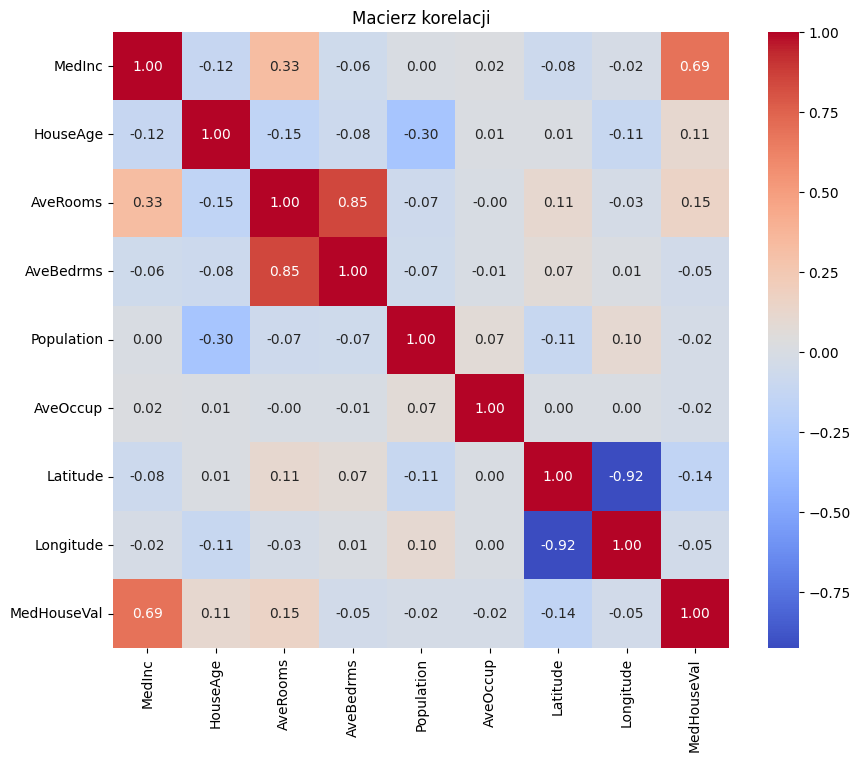

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Obliczenie macierzy korelacji bezpośrednio w tej komórce
oryginal_cols = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude", "MedHouseVal"]
corr = df[oryginal_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title("Macierz korelacji")
plt.show()

In [45]:
# Wykrywanie wartosci skrajnych IQR
# + Wizualizacja granic IQR

Q1= df["MedHouseVal"].quantile(0.25)
Q3 = df["MedHouseVal"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["MedHouseVal"] < lower_bound) | (df["MedHouseVal"] > upper_bound)
]

print("Q1 = ", round(Q1, 3))
print("Q3 = ", round(Q3, 3))
print("IQR = ", round(IQR, 3))
print("dolna granoca =", round(lower_bound, 3))
print("gorna granica =", round(upper_bound, 3))

print("\nLiczba wartosci skrajnych:", len(outliers))

Q1 =  1.196
Q3 =  2.647
IQR =  1.451
dolna granoca = -0.981
gorna granica = 4.824

Liczba wartosci skrajnych: 1071


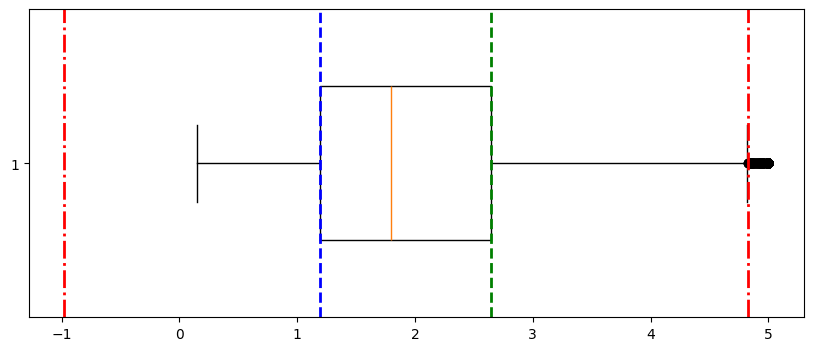

In [49]:
# Wykres boxplot z granicami IQR

plt.figure(figsize=(10,4))
plt.boxplot(
    df["MedHouseVal"],
    vert=False,
    widths=0.5
)

plt.axvline(
    Q1,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Q1 = {Q1:.2f}"
)

plt.axvline(
    Q3,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Q3 = {Q3:.2f}"
)

plt.axvline(
    lower_bound,
    color="red",
    linestyle="-.",
    linewidth=2,
    label=f"dolna granica = {lower_bound:.2f}"
)

plt.axvline(
    upper_bound,
    color="red",
    linestyle="-.",
    linewidth=2,
    label=f"dolna granica = {upper_bound:.2f}"
)

Text(249.87966304962492, 0.5, 'Latitude')

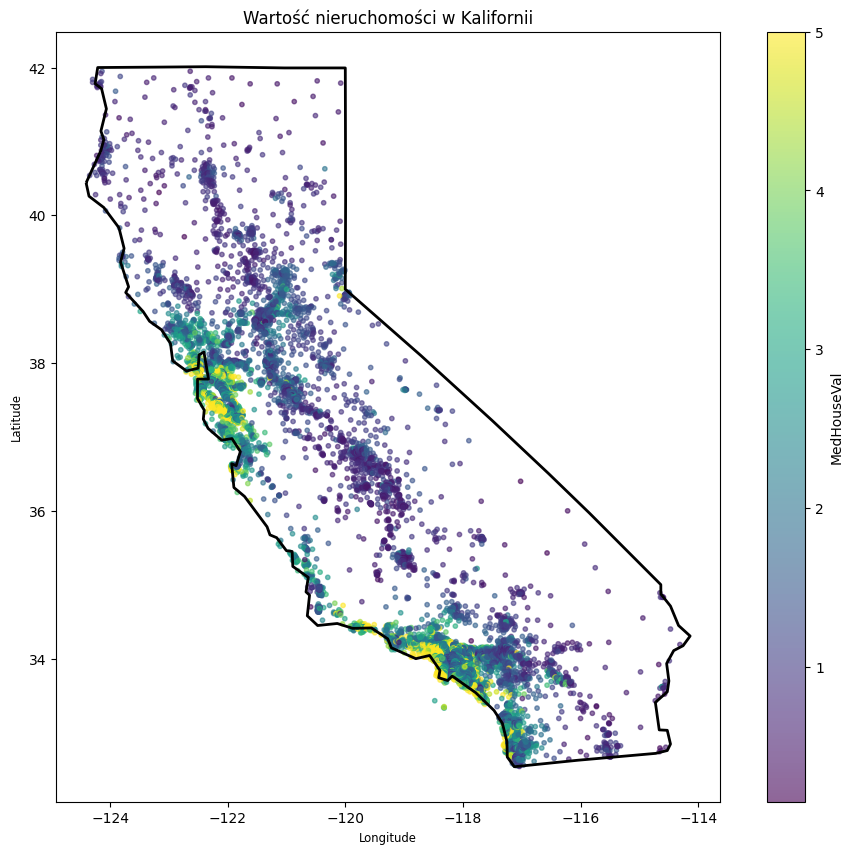

In [69]:
!pip -q install geopandas

import geopandas as gpd

usa = gpd.read_file(
    "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json")

california = usa[usa["name"] == 'California']

fig, ax = plt.subplots(figsize=(12,10))

california.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2
)

scatter = ax.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    s=10,
    alpha=0.6
)

cbar = plt.colorbar(scatter)
cbar.set_label("MedHouseVal")

ax.set_title("Wartość nieruchomości w Kalifornii")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

In [66]:
# California housing na tle zdjecia satelitarnego

!pip -q install geopandas contextily

import geopandas as gpd
import contextily as cx



In [68]:
# Punkty GIS

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["Longitude"],
        df["Latitude"]
    ),
    crs = "EPSG:4326"
)

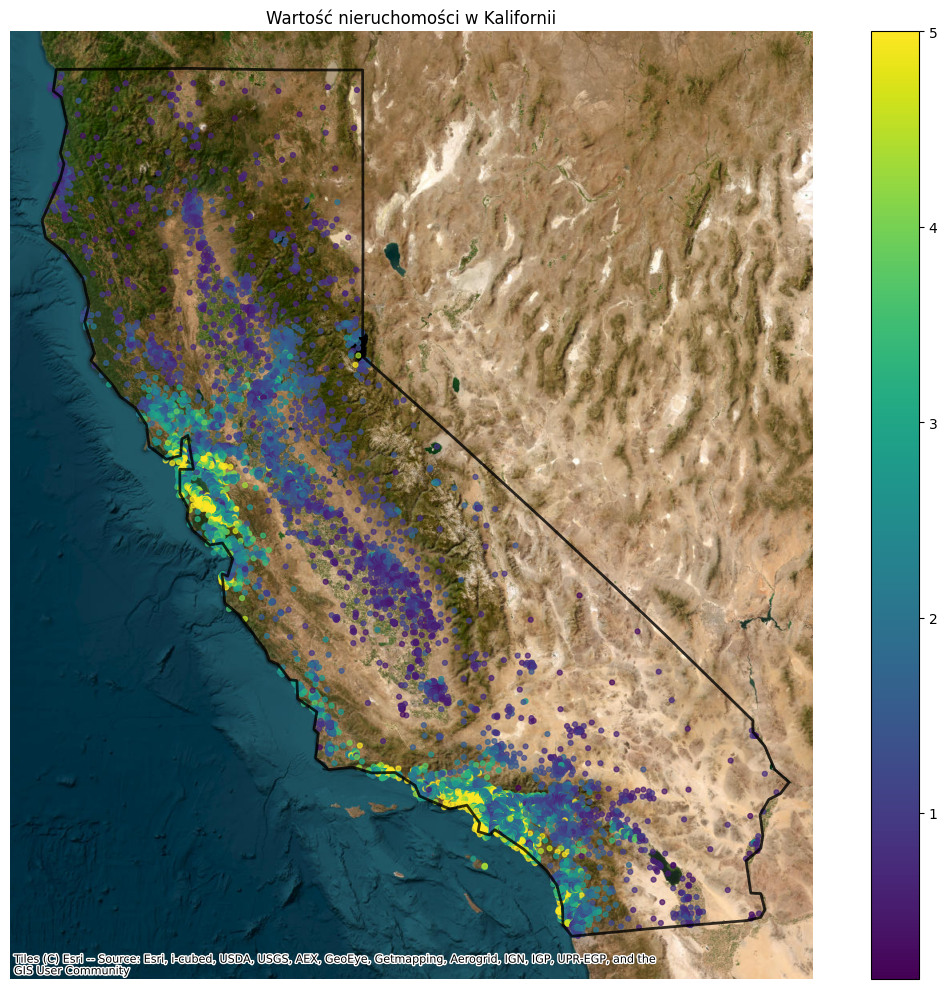

In [6]:
!pip -q install geopandas contextily

import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Upewniamy się, że dane 'df' oraz 'gdf' są załadowane i poprawne
try:
    _ = df.shape
except NameError:
    housing = fetch_california_housing(as_frame=True)
    df = housing.frame

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["Longitude"],
        df["Latitude"]
    ),
    crs="EPSG:4326"
)

usa = gpd.read_file(
    "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json")

california = usa[usa["name"] == "California"]

# Transformacja do Web mercator przez contextily
gdf = gdf.to_crs(epsg=3857)
california = california.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12,10))

gdf.plot(
    ax=ax,
    column="MedHouseVal",
    cmap="viridis",
    markersize=12,
    alpha=0.7,
    legend=True
)

cx.add_basemap(
    ax,
    source=cx.providers.Esri.WorldImagery
)

california.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2,
    alpha=0.8,
    zorder=100
)

ax.set_title("Wartość nieruchomości w Kalifornii")
ax.set_axis_off()
plt.tight_layout()
plt.show()